# Indian Startup Funding: Exploratory Data Analysis (Task 2)

**Goal:** understand funding trends, industries, cities, investors and funding stages.

**Data:** `cleaned_startup_funding.csv` (3,044 rows, 10 columns), the output of Task 1.

## 1. Data Audit

We first check the shape, data types, missing values, `Unknown` labels and duplicates.

**Next:** outlier detection.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/cleaned_startup_funding.csv', parse_dates = ['date'])

print(df.shape)
df.info()

print(df.isna().sum())
print((df == 'Unknown').sum())
# print(df.duplicated().sum())
print('Duplicates:', df.drop(columns='sr_no').duplicated().sum())
pd.options.display.float_format = '{:,.0f}'.format
df.describe()

(3044, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   sr_no            3044 non-null   int64         
 1   date             3044 non-null   datetime64[ns]
 2   startup_name     3044 non-null   object        
 3   industry         3044 non-null   object        
 4   subvertical      3044 non-null   object        
 5   city             3044 non-null   object        
 6   investors        3044 non-null   object        
 7   investment_type  3044 non-null   object        
 8   amount_usd       2073 non-null   float64       
 9   remarks          3044 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(7)
memory usage: 237.9+ KB
sr_no                0
date                 0
startup_name         0
industry             0
subvertical          0
city                 0
investors            0
in

,sr_no,date,amount_usd
count,"3,044",3044,"2,073"
mean,"1,522",2016-09-22 04:00:18.922470400,"18,400,345"
min,1,2015-01-02 00:00:00,"16,000"
25%,762,2015-11-03 00:00:00,"486,000"
50%,"1,522",2016-07-14 00:00:00,"1,750,000"
75%,"2,283",2017-06-12 00:00:00,"8,000,000"
max,"3,044",2020-01-13 00:00:00,"3,900,000,000"
std,879,NaN,"121,140,713"


## 2. Outlier Detection

`describe()` shows the mean amount (about \$18.4M) is far above the median (\$1.75M), and the maximum is \$3.9B. This suggests a few extreme values are pulling the average up.

First, we list the 40 largest amounts and check which ones look unrealistic.

**Next:** flag rows above \$100M as `suspect`.

In [3]:
df.nlargest(40, 'amount_usd')[['date', 'startup_name', 'investment_type', 'amount_usd']]

,date,startup_name,investment_type,amount_usd
60,2019-08-27,Rapido Bike Taxi,Series B,"3,900,000,000"
651,2017-08-11,Flipkart,Private Equity,"2,500,000,000"
830,2017-05-18,Paytm,Private Equity,"1,400,000,000"
966,2017-03-21,Flipkart,Private Equity,"1,400,000,000"
31,2019-11-25,Paytm,Other,"1,000,000,000"
2648,2015-07-28,Flipkart.com,Private Equity,"700,000,000"
2459,2015-09-29,Paytm,Private Equity,"680,000,000"
188,2018-08-30,True North,Private Equity,"600,000,000"
33,2019-10-02,Udaan,Series D,"585,000,000"
2244,2015-11-18,Ola,Private Equity,"500,000,000"


### 2.1 Quick check for unrealistic amounts

The top 40 list contains very large amounts, some of which look unrealistic. We flag every deal above \$100M as `suspect`, and separately list Seed/Angel deals of \$50M or more, because a seed round that large is very unlikely.

**Note:** `suspect` is only a "look here" list. It also contains real large deals such as Flipkart and Udaan.

In [4]:
print((df.select_dtypes('object')=='').sum())
df['suspect']=df.amount_usd>1e8
print(df.suspect.sum())
df[(df.investment_type=='Seed/Angel')&(df.amount_usd>=5e7)][['date','startup_name','amount_usd']]

startup_name       0
industry           0
subvertical        0
city               0
investors          0
investment_type    0
remarks            0
dtype: int64
56


,date,startup_name,amount_usd
9,2019-12-03,Dhruva Space,"50,000,000"
15,2019-12-11,Rein Games,"50,000,000"
27,2019-11-19,Digital Mall Asia,"220,000,000"
95,2019-05-28,FreshVnF,"140,000,000"
358,2018-02-08,Shape,"100,000,000"


**Result:** 56 deals are above \$100M, and 5 Seed/Angel deals are \$50M or more: Digital Mall Asia, FreshVnF, Shape, Rein Games and Dhruva Space. A \$220M Seed/Angel round is not realistic.

**Next:** a fairer outlier rule that depends on the round type.

### 2.2 Outliers within each investment type

A normal deal size differs by round, so a flat cut-off is unfair. We flag amounts above Q3 + 3 × IQR **within each investment type**. Using 3 instead of the usual 1.5 means only extreme values are flagged.

**Note:** this is a flag, not a decision. Very small groups cannot be tested well with this rule.

In [5]:
def flag(g):
  q1, q3=g.quantile(.25), g.quantile(.75)
  return g>q3+3*(q3-q1)

df['outlier']=df.groupby('investment_type').amount_usd.transform(flag)
print(df.outlier.sum())
df[df.outlier].groupby('investment_type').size()


118


,0
investment_type,
Other,1
Pre-Series A,1
Private Equity,82
Seed/Angel,28
Series A,1
Series B,3
Series C,1
Series D,1


**Result:** 118 rows are flagged, mostly Private Equity (82) and Seed/Angel (28).

**Next:** review the flagged rows by hand.

### 2.3 Manual review of flagged rows

We review the flagged Seed/Angel rows first, sorted by amount, to see which amounts are unrealistic for a seed round.

In [6]:
cols = ['date','startup_name','investment_type','amount_usd']

# Seed/Angel: 28 (Chances of getting suspect is high here)
df[df.outlier & (df.investment_type=='Seed/Angel')].sort_values('amount_usd', ascending=False)[cols]


,date,startup_name,investment_type,amount_usd
27,2019-11-19,Digital Mall Asia,Seed/Angel,"220,000,000"
95,2019-05-28,FreshVnF,Seed/Angel,"140,000,000"
358,2018-02-08,Shape,Seed/Angel,"100,000,000"
15,2019-12-11,Rein Games,Seed/Angel,"50,000,000"
9,2019-12-03,Dhruva Space,Seed/Angel,"50,000,000"
273,2018-05-27,Acko,Seed/Angel,"12,000,000"
145,2018-10-02,Origo Commodities India Pvt. Ltd,Seed/Angel,"11,000,000"
2240,2015-11-17,StyleTag,Seed/Angel,"7,500,000"
224,2018-07-31,Healthsignz,Seed/Angel,"5,000,000"
176,2018-08-13,Inthree,Seed/Angel,"4,000,000"


**Result:** 28 Seed/Angel rows are flagged. The top 5 (\$50M to \$220M) are far too large for a seed round. The other 23 range from \$2.4M to \$12M, which is high but possible, so they are left unchanged.

In [7]:

# Series B - 3
df[df.outlier & (df.investment_type=='Series B')][cols]

,date,startup_name,investment_type,amount_usd
29,2019-11-15,Vogo Automotive,Series B,"283,000,000"
60,2019-08-27,Rapido Bike Taxi,Series B,"3,900,000,000"
135,2018-11-19,Automation Anywhere,Series B,"300,000,000"


**Result:** Vogo Automotive (\$283M) and Rapido Bike Taxi (\$3.9B) look unrealistic for a Series B round. Automation Anywhere (\$300M) is a large deal but looks possible, so it is not marked.

The remaining flagged types (Other, Pre-Series A, Series A, Series C and Series D) have one row each. We show `investors` and `city` as well, to judge whether each amount is realistic.

In [8]:
df[df.outlier & ~df.investment_type.isin(['Private Equity','Seed/Angel','Series B'])][cols + ['investors','city']]

,date,startup_name,investment_type,amount_usd,investors,city
31,2019-11-25,Paytm,Other,"1,000,000,000",Vijay Shekhar Sharma,Noida
33,2019-10-02,Udaan,Series D,"585,000,000","Altimeter Capital, DST Global",Bengaluru
42,2019-09-04,GOQii,Series C,"450,000,000",Bennett Coleman and Company Ltd (BCCL),Menlo Park
79,2019-06-04,Recykal,Pre-Series A,"26,000,000","Triton Investment Advisors, Pidilite Industrie...",Hyderabad
98,2019-04-16,Kuvera,Series A,"45,000,000",Eight Roads,Bengaluru


**Result:** five rows are flagged. GOQii (\$450M, Series C), Recykal (\$26M, Pre-Series A) and Kuvera (\$45M, Series A) were checked against 2019 news reports. GOQii raised about Rs 45 crore (roughly \$6M), Recykal raised \$2M and Kuvera raised \$4.5M, so all three are marked `to_verify`. Udaan (\$585M) and Paytm (\$1B) match news reports and are left unchanged.

### 2.4 Rows to verify

We mark the startups whose amounts look unrealistic as `to_verify`. These are checked against public news before any change is made.

In [9]:
verify = ['Digital Mall Asia','FreshVnF','Shape','Rein Games','Dhruva Space','Vogo Automotive','Rapido Bike Taxi','GOQii','Recykal','Kuvera']
df['to_verify'] = df.startup_name.isin(verify) & df.outlier
print(df.to_verify.sum())

10


### 2.5 Summary of outlier detection

**What I did**
- `describe()` showed a very large gap between the mean (about \$18.4M) and the median (\$1.75M), and a maximum of \$3.9B.
- Listed the 40 largest amounts and marked deals above \$100M as `suspect` (56 rows).
- Flagged outliers with an IQR rule applied **within each investment type** (upper limit = Q3 + 3 × IQR), because a normal deal size differs by round type. This flagged 118 rows (Private Equity 82, Seed/Angel 28, others 8).
- Reviewed the flagged Seed/Angel, Series B and remaining rows by hand. Ten rows looked unrealistic for their round and were marked `to_verify`.

**Decision**
- Outliers are **flagged, not deleted**. A row is changed only when public news reports confirm the correct amount.

### 2.6 Fixing the wrong amounts

The 10 rows marked `to_verify` were checked against public news reports from 2018 and 2019. Most of them were rupee amounts stored as USD (for example, Rs 22 Cr shown as \$220M), and Recykal and Kuvera were data-entry errors. The corrected USD amount goes into `amount_usd`, and the original value is kept in `amount_original`.

Furtados School of Music (\$200M) was not flagged by the IQR rule because its investment type group is very small, so it is corrected here as well (Rs 20 Cr, about \$2.8M).

In [10]:
# Keep the original amount (only on the first run)
if 'amount_original' not in df.columns:
    df['amount_original'] = df.amount_usd

# Correct amounts, checked against public news reports (2018-2019)
fix = {'Digital Mall Asia': 3_060_000,   # Rs 22 Cr
       'FreshVnF':          2_000_000,   # $2M reported
       'Rein Games':          700_000,   # Rs 5 Cr
       'Dhruva Space':        700_000,   # Rs 5 Cr
       'Vogo Automotive':   4_000_000,   # Rs 28.3 Cr
       'Rapido Bike Taxi': 54_000_000,   # Rs 390 Cr
       'Shape':               200_000,   # $200K reported
       'GOQii':             6_240_000,   # Rs 45 Cr
       'Recykal':           2_000_000,   # $2M reported
       'Kuvera':            4_500_000}   # $4.5M reported

m = df.to_verify
new = df.loc[m, 'startup_name'].map(fix)
assert new.notna().all(), 'a to_verify row has no fix'
df.loc[m, 'amount_usd'] = new

# Furtados was not flagged by the IQR rule (its group is tiny): Rs 20 Cr ~ $2.8M
f = df.startup_name.str.contains('Furtados') & (df.amount_original == 200_000_000)
df.loc[f, 'amount_usd'] = 2_800_000

df['amount_fixed'] = m | f
print(df.amount_fixed.sum())
df.loc[df.amount_fixed, ['startup_name','amount_original','amount_usd']]

11


,startup_name,amount_original,amount_usd
9,Dhruva Space,"50,000,000","700,000"
15,Rein Games,"50,000,000","700,000"
27,Digital Mall Asia,"220,000,000","3,060,000"
29,Vogo Automotive,"283,000,000","4,000,000"
30,Furtados School of Music,"200,000,000","2,800,000"
42,GOQii,"450,000,000","6,240,000"
60,Rapido Bike Taxi,"3,900,000,000","54,000,000"
79,Recykal,"26,000,000","2,000,000"
95,FreshVnF,"140,000,000","2,000,000"
98,Kuvera,"45,000,000","4,500,000"


**Result:** 11 rows were corrected: the 10 `to_verify` rows and Furtados School of Music. Together they carried about \$5.46B before the fix and about \$0.08B after it, so the fixes remove about \$5.4B from the total. The original amounts are kept in `amount_original`.

**Next:** run the outlier rule again on the corrected amounts.

### 2.7 Re-checking outliers after the fixes

We run the same IQR rule again on the corrected amounts to see how many flagged rows remain. The result is saved in a new column `outlier_after_fix`, so the first flags stay unchanged.

In [11]:
df['outlier_after_fix'] = df.groupby('investment_type').amount_usd.transform(flag)
print(df.outlier_after_fix.sum())
df[df.outlier_after_fix].groupby('investment_type').size()

110


,0
investment_type,
Other,1
Private Equity,82
Seed/Angel,24
Series A,1
Series B,1
Series D,1


In [12]:
df[df.outlier_after_fix & ~df.outlier][cols + ['investors','city']]

,date,startup_name,investment_type,amount_usd,investors,city
141,2018-11-24,Engineer.ai,Series A,"29,500,000","Lakestar and Jungle Ventures, Softbank’s DeepC...",India


**Result:** 110 rows are still flagged, down from 118. Seed/Angel dropped from 28 to 24 because four of the five corrected rows are no longer flagged, Series B dropped from 3 to 1, and the Pre-Series A and Series C flags are gone. One row is new in Series A (Engineer.ai, \$29.5M): it is only above the limit because the Series A threshold fell after Kuvera was corrected, so it is left unchanged. Private Equity (82) is a mixed group that includes real large deals such as Flipkart and Paytm, so these rows are left unchanged too.

**Next:** a year-wise view of deals, total funding and median deal size.

## 3. Year-wise Trend

We group the deals by year and compare the number of deals, the total funding and the median deal size. The median is used because a few very large deals pull the total up.

**Note:** `amount_usd` is missing for many rows, so we also count how many deals in each year have an amount.

In [13]:
df['year']=df.date.dt.year
yr=df.groupby('year').agg(deals=('sr_no','count'),
                          with_amount=('amount_usd','count'),
                          total=('amount_usd','sum'),
                          median=('amount_usd','median'))
yr['missing_pct']=(1-yr.with_amount/yr.deals)*100
yr

,deals,with_amount,total,median,missing_pct
year,,,,,
2015,936,654,"8,673,022,368","1,500,000",30
2016,993,586,"3,828,088,608","1,000,000",41
2017,687,456,"10,429,309,730","2,250,000",34
2018,310,265,"5,022,568,369","3,800,000",15
2019,111,105,"4,416,918,535","6,240,000",5
2020,7,7,"390,207,254","9,000,000",0


**Result:** the number of deals falls from 993 in 2016 to 111 in 2019, and 2020 has only 7 deals (January). The share of deals with a missing amount also falls, from 41% in 2016 to 5% in 2019, so the totals of the earlier years are understated more than the later ones. The median deal size rises from \$1.0M in 2016 to \$6.2M in 2019. Total funding peaks at \$10.4B in 2017.

**Note:** the drop in the number of deals may partly reflect how the data was collected, not only the market.

**Next:** charts of the three measures.

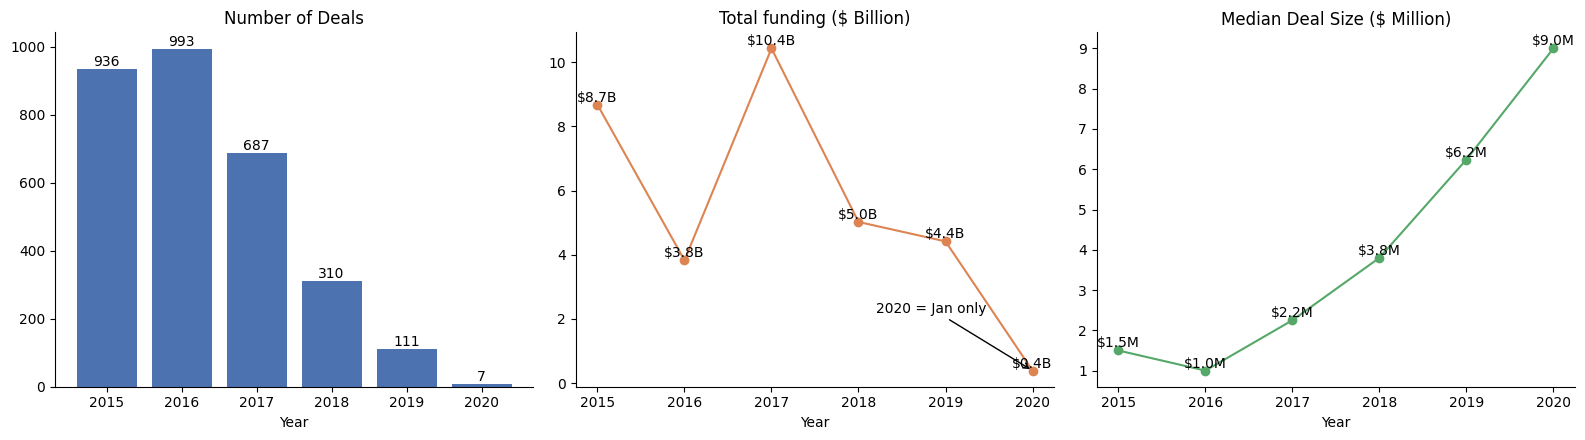

In [14]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(16,4.5))

ax[0].bar(yr.index,yr.deals,color='#4C72B0')
ax[0].set_title('Number of Deals')
for x,v in zip(yr.index,yr.deals):
  ax[0].text(x,v, f'{v:,}', ha='center', va='bottom')


ax[1].plot(yr.index,yr.total/1e9, marker='o', color= '#DD8452')
ax[1].set_title('Total funding ($ Billion)')
ax[1].annotate('2020 = Jan only', xy=(2020, yr.loc[2020,'total']/1e9), xytext=(2018.2,2.2),
               arrowprops=dict(arrowstyle='->'))
for x,v in zip(yr.index,yr.total/1e9):
  ax[1].text(x,v, f'${v:.1f}B', ha='center', va='bottom')


ax[2].plot(yr.index,yr['median']/1e6, marker='o', color= '#55A868')
ax[2].set_title('Median Deal Size ($ Million)')
for x,v in zip(yr.index,yr['median']/1e6):
  ax[2].text(x,v, f'${v:.1f}M', ha='center', va='bottom')



for a in ax:
  a.set_xlabel('Year')
  a.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()


**Findings**
- The number of deals falls every year after 2016 (993 to 111 in 2019), but the median deal size keeps rising (\$1.0M in 2016 to \$6.2M in 2019). Fewer, larger deals are what the data shows.
- Total funding does not follow the number of deals: it peaks in 2017 (\$10.4B) because of a few very large deals, then falls to about \$5B in 2018 and 2019.

**Caveats**
- 2020 contains only January (7 deals), so it cannot be compared with the full years.
- The share of deals with a missing amount falls from 41% in 2016 to 5% in 2019, so the earlier totals are understated more than the later ones.
- The drop in the number of deals may partly reflect how the data was collected, not only the market.

## 4. Industry-wise Funding

We group the deals by industry and compare the number of deals, the total funding and the median deal size. We keep only industries with at least 10 deals that have an amount, so that the median is reliable and a few one-off labels do not distort the ranking.

**Note:** deals with an `Unknown` industry are excluded.

In [15]:
d = df[df.industry != 'Unknown']
ind = d.groupby('industry').agg(deals=('sr_no','count'),
                                with_amount=('amount_usd','count'),
                                total=('amount_usd','sum'),
                                median=('amount_usd','median'))
ind[ind.with_amount >= 10].nlargest(10, 'total')

,deals,with_amount,total,median
industry,,,,
eCommerce,299,205,"8,043,795,693","3,000,000"
Consumer Internet,941,589,"6,253,084,245","1,000,000"
Technology,489,321,"2,305,167,930","1,500,000"
Finance,62,57,"1,930,938,000","6,000,000"
FinTech,16,16,"1,364,911,265","10,000,000"
Food & Beverage,35,25,"368,551,195","2,000,000"
Healthcare,70,44,"281,418,000","2,100,000"
Logistics,32,23,"242,845,000","6,000,000"
EdTech,20,18,"193,496,065","886,250"


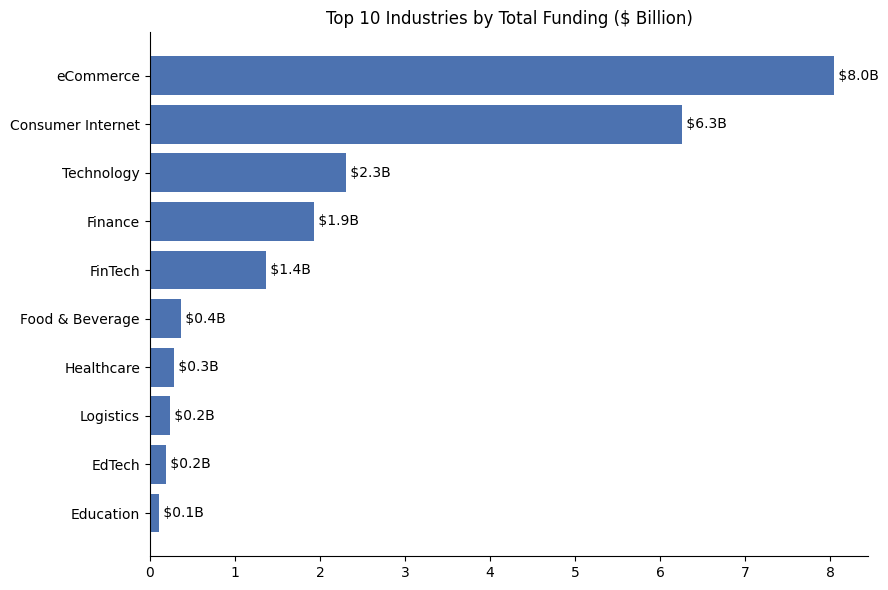

In [16]:
top = ind[ind.with_amount >= 10].nlargest(10, 'total')

fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top.index[::-1], top['total'][::-1]/1e9, color='#4C72B0')
ax.set_title('Top 10 Industries by Total Funding ($ Billion)')
for i, v in enumerate(top['total'][::-1]/1e9):
    ax.text(v, i, f' ${v:.1f}B', va='center')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Findings**
- eCommerce (\$8.0B) and Consumer Internet (\$6.3B) together hold about 68% of the top-10 funding.
- Consumer Internet has the most deals (941) but one of the lowest medians (\$1.0M), so it is many small deals. eCommerce has a higher median (\$3.0M).
- FinTech (median \$10M), Finance (\$6.0M) and Logistics (\$6.0M) have fewer but larger deals.

**Caveats**
- Industry labels are free text, so similar labels (for example `EdTech` and `Education`) stay separate.
- About a third of the deals in the largest industries have no amount (31% in eCommerce, 37% in Consumer Internet), so the totals are understated.
- Only industries with at least 10 deals that have an amount are shown, and 171 rows with an `Unknown` industry are excluded.

**Next:** the same view by city.

## 5. City-wise Funding

We first check the city labels for spelling variants (for example Bangalore and Bengaluru), because variants would split one city into several rows. Then we group the deals by city and compare the number of deals, the total funding and the median deal size.

In [17]:
df.city.value_counts().head(30)

,count
city,
Bengaluru,849
Mumbai,573
New Delhi,462
Gurugram,342
Unknown,180
Pune,112
Hyderabad,100
Chennai,98
Noida,94


In [18]:
df.city.value_counts().iloc[30:]

,count
city,
Udaipur,2
Siliguri,2
Udupi,2
Thiruvananthapuram,2
US,2
USA,2
"San Jose,",1
Tulangan,1
Amritsar,1


**Result:** the labels are mostly clean, but a few are misspelled or are neighbourhoods of a larger city (for example `Kormangala`, `Andheri` and `Taramani`). Some labels are not Indian cities (for example `Singapore`, `India` and `USA`) or contain two cities (for example `Bengaluru and Gurugram`).

**Next:** merge the clear spelling variants and neighbourhoods into their city. The other labels are left as they are, because they are small and do not reach the top 10.

### 5.1 Merging city labels

We map the clear typos, neighbourhoods and codes to their city (or country) in a new column `city_clean`. Labels that hold two cities or only a state are left as they are, because we cannot tell which city they mean. The original `city` column is kept unchanged.

In [19]:
city_fix = {'Kormangala':'Bengaluru', 'Andheri':'Mumbai', 'Chembur':'Mumbai',
            'Taramani':'Chennai', 'Nw Delhi':'New Delhi', 'Kolkatta':'Kolkata',
            'Ahemdabad':'Ahmedabad', 'Bhubneswar':'Bhubaneswar',
            'San Jose,':'San Jose', 'SFO':'San Francisco', 'US':'USA'}

df['city_clean'] = df.city.replace(city_fix)
print((df.city != df.city_clean).sum())

13


### 5.2 Funding by city

We group the deals by `city_clean` and keep the cities with at least 10 deals that have an amount. Deals with an `Unknown` city are excluded.

In [20]:
d = df[df.city_clean != 'Unknown']
cities = d.groupby('city_clean').agg(deals=('sr_no','count'),
                                     with_amount=('amount_usd','count'),
                                     total=('amount_usd','sum'),
                                     median=('amount_usd','median'))
cities[cities.with_amount >= 10].nlargest(10, 'total')

,deals,with_amount,total,median
city_clean,,,,
Bengaluru,851,593,"14,599,108,863","2,200,000"
Mumbai,575,409,"4,826,644,620","2,000,000"
Gurugram,342,244,"3,878,113,658","2,500,000"
New Delhi,463,270,"3,152,231,515","1,000,000"
Noida,94,57,"1,233,864,000","1,000,000"
Chennai,99,76,"756,847,000","2,500,000"
Pune,112,77,"617,782,000","1,300,000"
Hyderabad,100,73,"377,676,230","1,000,000"
Jaipur,30,14,"152,735,000","1,000,000"


### 5.3 Delhi NCR

`Delhi NCR` is not a label in the data. We add up the deals of New Delhi, Gurugram and Noida to see the region as a whole. Other nearby cities (for example Faridabad) are not included.

In [21]:
ncr = df[df.city_clean.isin(['New Delhi','Gurugram','Noida'])]
pd.Series({'deals': len(ncr),
           'with_amount': ncr.amount_usd.count(),
           'total': ncr.amount_usd.sum()})

,0
deals,899
with_amount,571
total,"8,264,209,173"


**Result:** Delhi NCR (New Delhi, Gurugram and Noida together) has 899 deals, of which 571 have an amount, and raised about \$8.3B. Bengaluru has 851 deals, of which 593 have an amount, and raised about \$14.6B. So NCR has more deals than Bengaluru but less money.

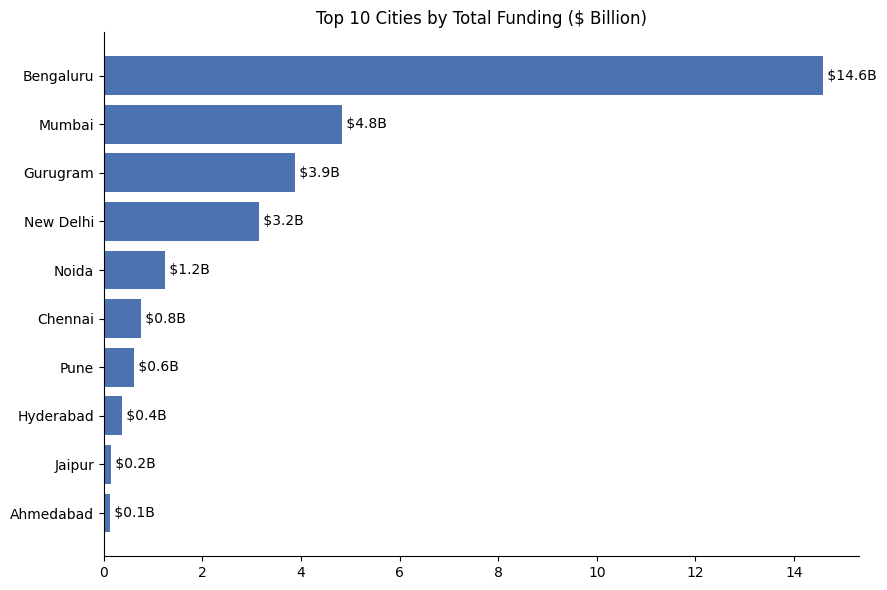

In [22]:
topc = cities[cities.with_amount >= 10].nlargest(10, 'total')

fig, ax = plt.subplots(figsize=(9,6))
ax.barh(topc.index[::-1], topc['total'][::-1]/1e9, color='#4C72B0')
ax.set_title('Top 10 Cities by Total Funding ($ Billion)')
for i, v in enumerate(topc['total'][::-1]/1e9):
    ax.text(v, i, f' ${v:.1f}B', va='center')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Findings**
- Bengaluru leads with about \$14.6B, roughly half of the top-10 city total (\$29.7B). Mumbai (\$4.8B) is second among single cities.
- Delhi NCR (New Delhi, Gurugram and Noida together) raised about \$8.3B, so it is the second-largest hub. It has more deals than Bengaluru (899 vs 851) but much less money.
- The median deal size is between \$1.0M and \$2.5M in all ten cities, so Bengaluru's lead in total comes mostly from a few very large deals, not from a higher typical deal.

**Caveats**
- `Delhi NCR` is not a label in the data. It is the sum of three city labels, and the chart shows these three cities separately.
- About a third of the deals have no amount (30% in Bengaluru, 36% in Delhi NCR), so the totals are understated.
- 180 rows with an `Unknown` city are excluded, and cities with fewer than 10 deals that have an amount are not shown.
- Labels with two cities or only a state were left as they are, and only clear typos and neighbourhoods were merged.

**Next:** the most active investors.

## 6. Top Investors

Each deal can have several investors in one row, separated by commas. We split them, so every investor gets credit for every deal they joined, and we rank investors by the number of deals. We first check the labels for spelling variants and for entries that are not real investors, because these would split or distort the counts.

In [23]:
inv = df.investors.str.split(',').explode().str.strip()
inv = inv[inv != '']
print('labels with "and", "&", ";" or "/":', inv.str.contains(r' and | & |;|/', case=False).sum())
inv.value_counts().head(40)

labels with "and", "&", ";" or "/": 449


,count
investors,
Sequoia Capital,72
Accel Partners,69
Kalaari Capital,50
SAIF Partners,48
Blume Ventures,47
Indian Angel Network,42
Undisclosed Investors,39
Undisclosed,35
Ratan Tata,31


In [24]:
key = 'Sequoia|Accel|Tiger|IDG|Kalaari|SAIF|Blume|Nexus|Matrix'
print(inv[inv.str.contains(key, case=False)].value_counts().head(25))
print()
print(inv[inv.str.contains(r' and | & |;|/', case=False)].sample(25, random_state=1).tolist())

investors
Sequoia Capital                        72
Accel Partners                         69
Kalaari Capital                        50
SAIF Partners                          48
Blume Ventures                         47
Nexus Venture Partners                 30
Tiger Global                           28
IDG Ventures                           28
Matrix Partners                        24
Sequoia India                          22
Tiger Global Management                21
IDG Ventures India                     18
Sequoia Capital India                  16
Matrix Partners India                  10
WaterBridge Ventures                    5
GHV Accelerator                         4
Accel Partners India                    4
Accel India                             3
Accel                                   3
Kalaari Capital Accelerator Program     3
Sequoia                                 2
Blume Ventures & Others                 2
Accel Partner                           2
Accel Partners & Others 

### 6.1 Cleaning the investor names

We clean the investor names before counting:
- generic endings such as `& Others` or `and existing investors` are removed, so the investor name stays;
- clear name variants are merged (for example `Sequoia India` and `Sequoia Capital India` into `Sequoia Capital`);
- generic labels such as `Undisclosed` are removed;
- an investor is counted once per deal.

Labels that join two named investors (for example `Premji Invest & Mayfield Fund`) are not split, because some real names also contain `&` or `and`.

In [25]:
inv = df[['sr_no','investors']].copy()
inv['investor'] = inv.investors.str.split(',')
inv = inv.explode('investor')
inv['investor'] = inv.investor.str.strip()

# remove generic endings such as "& Others" or "and existing investors"
tail = r'\s*(?:&|and)\s+(?:others?\b|existing\b|one more\b).*$'
inv['investor'] = inv.investor.str.replace(tail, '', regex=True, case=False).str.strip()

inv_fix = {'Sequoia India':'Sequoia Capital', 'Sequoia Capital India':'Sequoia Capital', 'Sequoia':'Sequoia Capital',
           'Accel Partners India':'Accel Partners', 'Accel India':'Accel Partners',
           'Accel':'Accel Partners', 'Accel Partner':'Accel Partners',
           'Tiger Global Management':'Tiger Global',
           'IDG Ventures India':'IDG Ventures',
           'Matrix Partners India':'Matrix Partners'}
inv['investor'] = inv.investor.replace(inv_fix)

generic = r'undisclosed|existing investors|^others?$|group of angel investors'
inv = inv[(inv.investor != '') & ~inv.investor.str.contains(generic, case=False)]
inv = inv.drop_duplicates(['sr_no','investor'])

inv.investor.value_counts().head(10)

,count
investor,
Sequoia Capital,112
Accel Partners,84
Tiger Global,52
Blume Ventures,51
Kalaari Capital,51
SAIF Partners,50
IDG Ventures,46
Indian Angel Network,43
Matrix Partners,34


**Result:** after cleaning the names, Sequoia Capital (112) and Accel Partners (84) are the most active investors, followed by Tiger Global (52), Blume Ventures (51) and Kalaari Capital (51). Merging the name variants raised Sequoia Capital from 72 to 112 and Tiger Global from 28 to 52, so the ranking is different from the one based on the raw labels.

**Next:** a chart of the top 10.

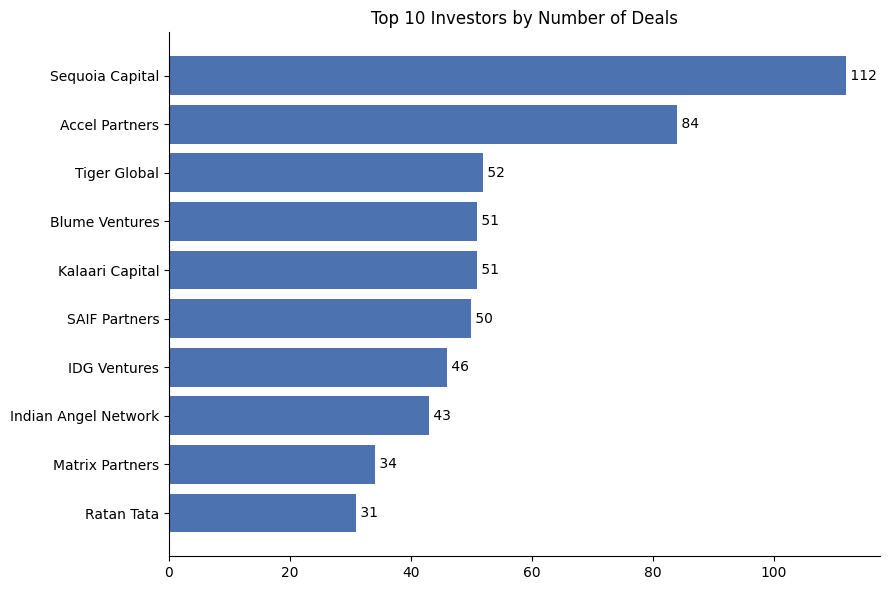

In [26]:
top_inv = inv.investor.value_counts().head(10)

fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top_inv.index[::-1], top_inv.values[::-1], color='#4C72B0')
ax.set_title('Top 10 Investors by Number of Deals')
for i, v in enumerate(top_inv.values[::-1]):
    ax.text(v, i, f' {v}', va='center')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Findings**
- Sequoia Capital (112 deals) and Accel Partners (84) are the most active investors, well ahead of Tiger Global (52).
- Individual angels such as Ratan Tata (31 deals) rank alongside venture funds, and Indian Angel Network (43) is a group of angels.

**Caveats**
- The ranking is by number of deals, not by the amount invested.
- A row with several investors is split, so each investor gets credit for every deal they joined, and counts once per deal.
- `Undisclosed` and other generic labels were removed, and the clear name variants were merged. Other variants may remain.
- Labels that join two named investors (for example `Premji Invest & Mayfield Fund`) were not split, so those investors are slightly undercounted.

**Next:** funding by investment type.

## 7. Funding by Investment Type

We group the deals by investment type and compare the number of deals, the total funding and the median deal size. Deals with an `Unknown` investment type are excluded.

**Note:** `Private Equity` is a mixed group, so its median is not comparable with the numbered rounds (Series A, B, ...).

In [27]:
d = df[df.investment_type != 'Unknown']
it = d.groupby('investment_type').agg(deals=('sr_no','count'),
                                      with_amount=('amount_usd','count'),
                                      total=('amount_usd','sum'),
                                      median=('amount_usd','median'))
it.sort_values('deals', ascending=False)

,deals,with_amount,total,median
investment_type,,,,
Seed/Angel,1542,864,"502,941,523","363,000"
Private Equity,1367,1082,"27,397,248,165","6,000,000"
Debt,31,30,"192,423,174","4,900,000"
Series A,24,22,"162,700,000","4,000,000"
Series B,21,21,"680,195,735","15,109,500"
Series C,14,14,"600,958,394","44,040,000"
Series D,12,12,"1,481,799,000","65,000,000"
Other,11,8,"1,205,892,095","10,000,000"
Pre-Series A,9,8,"20,372,000","2,500,000"


**Result:** Private Equity holds about \$27.4B of the \$32.7B total (about 84%) in 1,367 deals. Seed/Angel has the most deals (1,542) but only about \$0.5B (1.5% of the total). The median deal size rises with the round: Seed/Angel \$0.36M, Series A \$4.0M, Series B \$15.1M, Series C \$44.0M and Series D \$65.0M.

**Note:** the `Other` group (\$1.2B) is mostly one deal, Paytm's \$1B round. Series E to J have only 1 or 2 deals each, so their medians are not reliable.

**Next:** a closer look at the Series J row, then a chart of the median deal size by round.

Series E to J have only 1 or 2 deals each. As an example, we look at the single Series J row.

In [28]:
df[df.investment_type=='Series J'][['date','startup_name','amount_usd','remarks']]

,date,startup_name,amount_usd,remarks
64,2019-07-03,Ola Cabs,"1,000,000",Not provided


**Result:** the only Series J row is Ola Cabs (\$1M, July 2019). Ola's Series J was a large round that was raised in several parts during 2019, so this row is only a small part of it. A single row like this cannot give a reliable median, so rounds beyond Series D are not compared. The amount was left unchanged because it does not match a reported amount for July 2019.

**Next:** a chart of the median deal size for Seed/Angel and Series A to D.

Rounds beyond Series D have only 1 or 2 deals each, so the chart shows only Seed/Angel and Series A to D. `Private Equity` is left out because it is a mixed group.

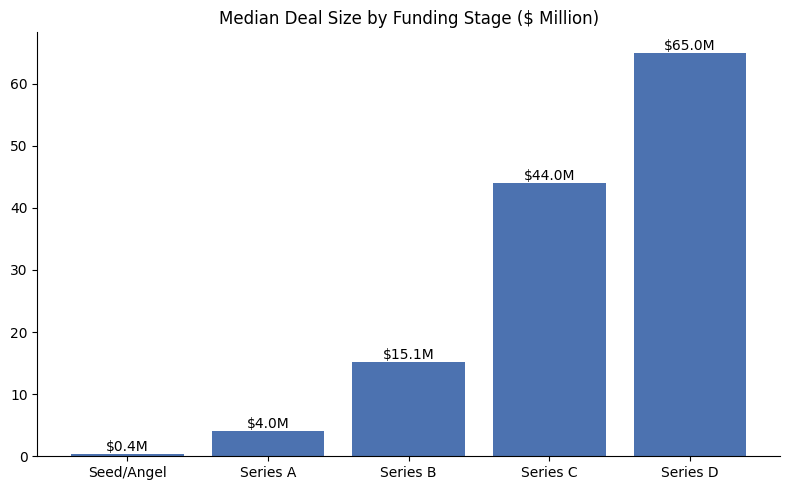

In [29]:
order = ['Seed/Angel','Series A','Series B','Series C','Series D']
m = it.loc[order, 'median']/1e6

fig, ax = plt.subplots(figsize=(8,5))
ax.bar(m.index, m.values, color='#4C72B0')
ax.set_title('Median Deal Size by Funding Stage ($ Million)')
for i, v in enumerate(m.values):
    ax.text(i, v, f'${v:.1f}M', ha='center', va='bottom')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Findings**
- Private Equity holds about 84% of the total funding, while Seed/Angel has the most deals (1,542) but only about 1.5% of the money.
- The median deal size rises with the round: \$0.36M (Seed/Angel), \$4.0M (Series A), \$15.1M (Series B), \$44.0M (Series C) and \$65.0M (Series D).

**Caveats**
- Series E to J have only 1 or 2 deals each, so their medians are not reliable. The Series J row (Ola Cabs, \$1M) is only a small part of a larger round.
- `Private Equity` mixes very different deals, and some rows may be fund raises, not startup funding.
- The `Other` group is mostly one deal (Paytm, \$1B).

**Next:** the top funded startups.

## 8. Top Startups by Funding

The same startup can appear under different spellings (for example `Ola` and `Ola Cabs`), which would split its total across several rows. Before ranking the startups, we look for name variants.

First, we find names that differ only by capital letters, spaces, punctuation or endings such as `.com` and `Pvt Ltd`.

In [30]:
import re

def name_key(s):
    s = re.sub(r'\.com|\.in|\bpvt\b|\bltd\b|\bprivate\b|\blimited\b', '', s.lower())
    return re.sub(r'[^a-z0-9]', '', s)

names = df[['startup_name']].copy()
names['key'] = names.startup_name.map(name_key)
variants = names.groupby('key').startup_name.agg(lambda x: sorted(x.unique()))
variants[variants.map(len) > 1]

,startup_name
key,
activeai,"[Active AI, Active.ai]"
applop,"[AppLop, Applop]"
appsdaily,"[AppsDaily, Appsdaily]"
availfinance,"[Avail Finance, AvailFinance]"
ayefinance,"[AYE Finance, Aye Finance, AyeFinance]"
...,...
zendrive,"[ZenDrive, Zendrive]"
zenify,"[Zenify, Zenify.in]"
zestmoney,"[Zest Money, ZestMoney]"


**Result:** 189 startups appear under more than one spelling. These spellings differ only by capital letters, spaces or punctuation (for example `ZoomCar` and `Zoomcar`, or `AYE Finance` and `AyeFinance`).

**Next:** merge them automatically, then handle names that use different words.

### 8.1 Merging name variants

All spellings that differ only by capital letters, spaces, punctuation or endings such as `.com` are mapped to the most common spelling, in a new column `startup_clean`. The original `startup_name` is kept unchanged. Names that use different words (for example `Ola` and `Ola Cabs`) are checked in the next step.

In [31]:
canon = names.groupby('key').startup_name.agg(lambda x: x.value_counts().idxmax())
df['startup_clean'] = names.key.map(canon)

print(df.startup_name.nunique(), '->', df.startup_clean.nunique())
df.startup_clean[df.startup_clean.str.contains(r'^(?:ola|oyo)', case=False)].value_counts()

2457 -> 2244


,count
startup_clean,
Ola Cabs,9
OYO Rooms,8
Ola,4
Ola Electric,1
Oyo,1
OYOfit,1


**Result:** merging spellings that differ only by capital letters, spaces or punctuation reduced the unique startup names from 2,457 to 2,244.

**Note:** `Ola Cabs`, `Ola`, `OYO Rooms` and `Oyo` still appear separately because they use different words. `Ola Electric` and `OYOfit` are different companies, so they are not merged.

**Next:** merge the Ola and OYO names, then check the other big names (Flipkart, Paytm, BYJU'S and so on) the same way.

In [32]:
brand_fix = {'Ola Cabs': 'Ola', 'OYO Rooms': 'OYO', 'Oyo': 'OYO'}
df['startup_clean'] = df.startup_clean.replace(brand_fix)

# check: top 25 names by number of rows, to spot other split names
df.startup_clean.value_counts().head(25)

,count
startup_clean,
Ola,13
OYO,9
Aye Finance,8
Swiggy,8
Byju’s,7
Paytm,7
Lendingkart,7
Lenskart,7
HolaChef,6


In [33]:
df.loc[df.amount_fixed, ['startup_name','amount_original','amount_usd']]

,startup_name,amount_original,amount_usd
9,Dhruva Space,"50,000,000","700,000"
15,Rein Games,"50,000,000","700,000"
27,Digital Mall Asia,"220,000,000","3,060,000"
29,Vogo Automotive,"283,000,000","4,000,000"
30,Furtados School of Music,"200,000,000","2,800,000"
42,GOQii,"450,000,000","6,240,000"
60,Rapido Bike Taxi,"3,900,000,000","54,000,000"
79,Recykal,"26,000,000","2,000,000"
95,FreshVnF,"140,000,000","2,000,000"
98,Kuvera,"45,000,000","4,500,000"


**Result:** the Ola, OYO, Aye Finance, Byju's and Flipkart spellings are now merged. `Ola Electric`, `OYOfit` and `Paytm Marketplace` are kept separate because they are different companies or business units.

**Next:** rank the startups by total funding.

In [34]:
d = df[df.startup_clean != 'True North']   # a PE fund raise, not startup funding
top = (d.groupby('startup_clean').amount_usd
         .agg(deals='size', with_amount='count', total='sum')
         .nlargest(15, 'total'))
top

,deals,with_amount,total
startup_clean,,,
Flipkart,6,6,"4,759,700,000"
Paytm,7,5,"3,148,950,000"
Ola,13,12,"2,054,200,000"
OYO,9,9,"997,000,000"
Udaan,4,4,"870,000,000"
Snapdeal,2,2,"700,000,000"
Byju’s,7,6,"525,000,000"
BigBasket,5,5,"512,000,000"
Zomato,4,4,"435,000,000"


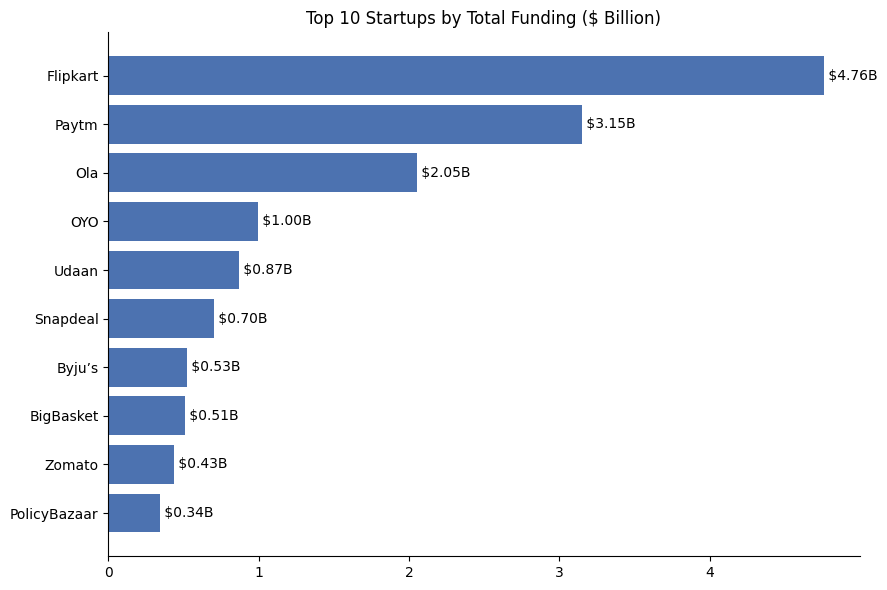

In [35]:
top10 = top.head(10)

fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top10.index[::-1], top10['total'][::-1]/1e9, color='#4C72B0')
ax.set_title('Top 10 Startups by Total Funding ($ Billion)')
for i, v in enumerate(top10['total'][::-1]/1e9):
    ax.text(v, i, f' ${v:.2f}B', va='center')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Findings**
- Flipkart (\$4.76B), Paytm (\$3.15B) and Ola (\$2.05B) are the top three. Together they hold about 69% of the top-10 funding (\$9.96B of \$14.35B).
- Ola has the most deals (13), but Flipkart raised more money in only 6 deals, so its rounds were much larger.
- OYO (\$1.0B) is fourth. Udaan, Snapdeal, Byju's, BigBasket, Zomato and PolicyBazaar are each between \$0.34B and \$0.87B.

**Caveats**
- Paytm's total includes a \$1B row from Nov 2019 where the only investor listed is Vijay Shekhar Sharma and the type is `Other`. Without it, Paytm would be \$2.15B, still third.
- `Paytm Marketplace`, `Ola Electric` and `OYOfit` are kept separate from their parent brands.
- Rows with a missing amount are not counted (for example Paytm has 7 deals but 5 with an amount).
- `True North` (\$600M, a private equity fund raise) is excluded.

## Key Takeaways

1. **Fewer, bigger deals:** deals fell from 993 (2016) to 111 (2019), while the median deal size rose from \$1.0M to \$6.2M.
2. **Funding is concentrated:** eCommerce (\$8.0B) and Consumer Internet (\$6.3B) lead by industry. Bengaluru (\$14.6B) is the top city, and Delhi NCR (New Delhi, Gurugram and Noida together, \$8.3B) is second.
3. **Stage matters:** the median deal size rises from \$0.36M (Seed/Angel) to \$65M (Series D). Private Equity holds about 84% of the total funding.
4. **Most active investors:** Sequoia Capital (112 deals) and Accel Partners (84), followed by Tiger Global (52).
5. **Top funded startups:** Flipkart (\$4.76B), Paytm (\$3.15B) and Ola (\$2.05B).

## Limitations

- About 32% of `amount_usd` is missing, so totals are understated (most in 2016).
- 11 rows with rupee amounts stored as USD were corrected after checking public news reports. The original values are kept in `amount_original`. Smaller cases of the same error may remain.
- 2020 contains only January (7 deals), so it cannot be compared with full years.
- Industry labels are free text, so similar labels (for example `EdTech` and `Education`) are not merged.
- Startup names that differ only by capital letters or punctuation were merged for all startups. Ola and OYO were merged by hand, and other names that use different words may remain split.
- Some Private Equity rows may be fund raises, not startup funding (`True North` was excluded).
- Series E to J have only 1 or 2 deals each, so their medians are not reliable.

## Export

The final analysis-ready table is saved as `startup_funding_eda.csv`. It keeps the corrected `amount_usd`, the original value in `amount_original`, and the merged `startup_clean` and `city_clean` columns.

In [36]:
# Columns to keep in the final file (skips any that do not exist)
final_cols = ['sr_no', 'date', 'year', 'startup_name', 'startup_clean', 'industry',
              'subvertical', 'city', 'city_clean', 'investors', 'investment_type',
              'amount_usd', 'amount_original', 'amount_fixed', 'outlier_after_fix', 'remarks']
final_cols = [c for c in final_cols if c in df.columns]

out = df[final_cols]

# Save to Google Drive
out.to_csv('/content/drive/MyDrive/startup_funding_eda.csv', index=False)

# Download to the local computer
from google.colab import files
files.download('/content/drive/MyDrive/startup_funding_eda.csv')

print(out.shape)
print(out.columns.tolist())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(3044, 16)
['sr_no', 'date', 'year', 'startup_name', 'startup_clean', 'industry', 'subvertical', 'city', 'city_clean', 'investors', 'investment_type', 'amount_usd', 'amount_original', 'amount_fixed', 'outlier_after_fix', 'remarks']
